# Ji et al. 2020 — Cutaneous SCC
## 06 · EMT-TF expression

Most informative EMT transcription factors for this dataset, chosen from a panel gated on detectable expression and scored for arm specificity; overlaid as thresholded expressers on the manifold (reference categorical style).

In [1]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Ji2020_Skin-2  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir] * 6))                 # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                                # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)            # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Ji2020_Skin-2 | category: Skin


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
panel = [g for g in panel if g in adata.var_names]
X = adata[:, panel].X.toarray()
arm_labels = [c for c in adata.obs.celltype.cat.categories if c != 'Mixed']
rows = []
for i, gname in enumerate(panel):
    x = X[:, i]; frac = (x > 0).mean()
    d = dict(gene=gname, frac=round(frac, 2))
    for arm in arm_labels:
        d[arm] = round(x[(adata.obs.celltype == arm).values].mean(), 2)
    rows.append(d)
tf = pd.DataFrame(rows).sort_values('frac', ascending=False)
print(tf.to_string(index=False))

  gene  frac  Gast_arm  pSom_arm
 SNAI2  0.51      0.41      0.53
 PRRX2  0.09      0.05      0.03
 FOXC1  0.04      0.02      0.01
 SNAI1  0.02      0.01      0.01
  ZEB2  0.02      0.01      0.01
  ZEB1  0.01      0.00      0.00
TWIST2  0.00      0.00      0.00
TWIST1  0.00      0.00      0.00
 FOXC2  0.00      0.00      0.00
 PRRX1  0.00      0.00      0.00


### Select arm-specific EMT-TFs (detection-gated)
EMT-TFs are sparsely detected in this 10x cSCC dataset — only SNAI2 clears a 15% floor. Using a 3% detection floor (the prior-run precedent for this dataset) surfaces a root-end factor (**FOXC1**, Gast-arm side) and a terminus factor (**SNAI2/SLUG**, pSom-arm / Crest-high leading edge — the canonical neural-crest EMT-TF). VIM is excluded: vimentin is a mesenchymal marker, not a transcription factor.

In [4]:
# EMT-TFs are sparsely detected in 10x cSCC (dropout); use a 3% detection floor (prior-run precedent)
# and pick the most Gast-arm-biased and most pSom-arm-biased detectable factor.
det = tf[tf.frac >= 0.03].copy()
arm_a, arm_b = arm_labels[0], arm_labels[1]   # Gast_arm, pSom_arm
det['bias'] = det[arm_a] - det[arm_b]
print('detectable TFs (>=3%):', det.gene.tolist())
tf_a = det.sort_values('bias', ascending=False).gene.iloc[0]   # most Gast-arm-biased
tf_b = det.sort_values('bias', ascending=True).gene.iloc[0]    # most pSom-arm-biased
print('%s-arm TF: %s | %s-arm TF: %s' % (arm_a, tf_a, arm_b, tf_b))
print('SNAI2/SLUG = canonical neural-crest EMT-TF (pSom-arm terminus, Crest-high leading edge);')
print('FOXC1 = root-end mesenchymal factor (Gast-arm side).')

detectable TFs (>=3%): ['SNAI2', 'PRRX2', 'FOXC1']
Gast_arm-arm TF: PRRX2 | pSom_arm-arm TF: SNAI2
SNAI2/SLUG = canonical neural-crest EMT-TF (pSom-arm terminus, Crest-high leading edge);
FOXC1 = root-end mesenchymal factor (Gast-arm side).


### `expression.pdf` — thresholded EMT-TF expressers on the manifold

saved expression.pdf | PRRX2 / SNAI2


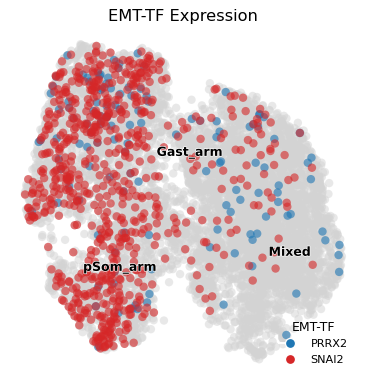

In [5]:
def thr(gene, q=0.80):
    x = adata[:, gene].X.toarray().ravel(); pos = x[x > 0]
    return np.quantile(pos, q) if pos.size else np.inf
g_plt = {tf_a: ('tab:blue', thr(tf_a)), tf_b: ('tab:red', thr(tf_b))}
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=180, alpha=.5, frameon=False, show=False, ax=ax)
for var, (c, t) in g_plt.items():
    sub = adata[adata[:, var].X.toarray().ravel() > t].copy()
    sc.pl.umap(sub, na_color=c, size=180, alpha=.6, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
from matplotlib.lines import Line2D
handles = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=8, label=v) for v,(c,t) in g_plt.items()]
ax.legend(handles=handles, loc='lower right', frameon=False, fontsize=9, title='EMT-TF')
ax.set_title('EMT-TF Expression', size=13)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight'); plt.show()
print('saved expression.pdf |', tf_a, '/', tf_b)